# KNN on the Hypertension Dataset
Flow (from the whiteboard): **CSV/Excel → pandas DataFrame → split → Training data fits KNN model → Test data evaluates the model (Accuracy, ROC-AUC)**

## 1. Load data (CSV → pandas DataFrame)

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
# In Colab use: pd.read_csv('/content/drive/MyDrive/Data mining & ML/hypertension_dataset (1).csv')
df = pd.read_csv('hypertension_dataset (1).csv')
df.head()

,Age,Salt_Intake,Stress_Score,BP_History,Sleep_Duration,BMI,Medication,Family_History,Exercise_Level,Smoking_Status,Has_Hypertension
0,69,8.0,9,Normal,6.4,25.8,NaN,Yes,Low,Non-Smoker,Yes
1,32,11.7,10,Normal,5.4,23.4,NaN,No,Low,Non-Smoker,No
2,78,9.5,3,Normal,7.1,18.7,NaN,No,Moderate,Non-Smoker,No
3,38,10.0,10,Hypertension,4.2,22.1,ACE Inhibitor,No,Low,Non-Smoker,Yes
4,41,9.8,1,Prehypertension,5.8,16.2,Other,No,Moderate,Non-Smoker,No


In [2]:
df.info(); print(df.isnull().sum()); print(df['Has_Hypertension'].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 1985 entries, 0 to 1984
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Age               1985 non-null   int64  
 1   Salt_Intake       1985 non-null   float64
 2   Stress_Score      1985 non-null   int64  
 3   BP_History        1985 non-null   str    
 4   Sleep_Duration    1985 non-null   float64
 5   BMI               1985 non-null   float64
 6   Medication        1186 non-null   str    
 7   Family_History    1985 non-null   str    
 8   Exercise_Level    1985 non-null   str    
 9   Smoking_Status    1985 non-null   str    
 10  Has_Hypertension  1985 non-null   str    
dtypes: float64(3), int64(2), str(6)
memory usage: 170.7 KB
Age                   0
Salt_Intake           0
Stress_Score          0
BP_History            0
Sleep_Duration        0
BMI                   0
Medication          799
Family_History        0
Exercise_Level        0
Smoking_Status   

## 2. Preprocess
Medication has missing values (blank = no medication), so fill with `'None'`. KNN uses distances, so categorical columns are one-hot encoded and numeric columns are **scaled**.

In [3]:
df['Medication'] = df['Medication'].fillna('None')
X = df.drop('Has_Hypertension', axis=1)
y = df['Has_Hypertension'].map({'No':0,'Yes':1})
X = pd.get_dummies(X, drop_first=True)
X.head()

,Age,Salt_Intake,Stress_Score,Sleep_Duration,BMI,BP_History_Normal,BP_History_Prehypertension,Medication_Beta Blocker,Medication_Diuretic,Medication_None,Medication_Other,Family_History_Yes,Exercise_Level_Low,Exercise_Level_Moderate,Smoking_Status_Smoker
0,69,8.0,9,6.4,25.8,True,False,False,False,True,False,True,True,False,False
1,32,11.7,10,5.4,23.4,True,False,False,False,True,False,False,True,False,False
2,78,9.5,3,7.1,18.7,True,False,False,False,True,False,False,False,True,False
3,38,10.0,10,4.2,22.1,False,False,False,False,False,False,False,True,False,False
4,41,9.8,1,5.8,16.2,False,True,False,False,False,True,False,False,True,False


## 3. Train / Test split
The scaler is fit on **training data only** to avoid data leakage.

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)

## 4. KNN model (start with k=1, like the lecture notebook)

In [5]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score
knn = KNeighborsClassifier(n_neighbors=1).fit(X_train_s, y_train)
pred = knn.predict(X_test_s)
print(confusion_matrix(y_test, pred)); print(classification_report(y_test, pred))

[[237  49]
 [ 81 229]]
              precision    recall  f1-score   support

           0       0.75      0.83      0.78       286
           1       0.82      0.74      0.78       310

    accuracy                           0.78       596
   macro avg       0.78      0.78      0.78       596
weighted avg       0.79      0.78      0.78       596



## 5. Choose best K (error rate vs K)

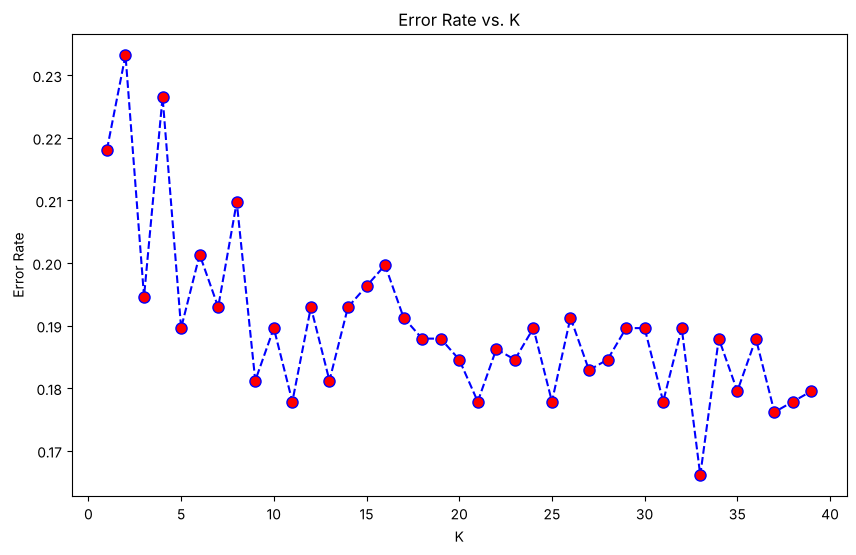

Best K: 33 error: 0.16610738255033558


In [6]:
error_rate = []
for i in range(1, 40):
    m = KNeighborsClassifier(n_neighbors=i).fit(X_train_s, y_train)
    error_rate.append(np.mean(m.predict(X_test_s) != y_test))
plt.figure(figsize=(10,6))
plt.plot(range(1,40), error_rate, color='blue', linestyle='dashed', marker='o', markerfacecolor='red', markersize=8)
plt.title('Error Rate vs. K'); plt.xlabel('K'); plt.ylabel('Error Rate'); plt.show()
best_k = int(np.argmin(error_rate)) + 1
print('Best K:', best_k, 'error:', min(error_rate))

## 6. Final model + ROC-AUC

[[261  25]
 [ 74 236]]
              precision    recall  f1-score   support

           0       0.78      0.91      0.84       286
           1       0.90      0.76      0.83       310

    accuracy                           0.83       596
   macro avg       0.84      0.84      0.83       596
weighted avg       0.84      0.83      0.83       596

Accuracy: 0.8338926174496645
ROC-AUC : 0.9268046469659373


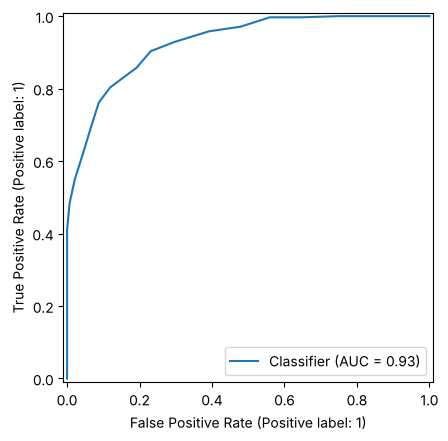

In [7]:
from sklearn.metrics import RocCurveDisplay
knn = KNeighborsClassifier(n_neighbors=best_k).fit(X_train_s, y_train)
pred  = knn.predict(X_test_s)
proba = knn.predict_proba(X_test_s)[:,1]
print(confusion_matrix(y_test, pred)); print(classification_report(y_test, pred))
print('Accuracy:', knn.score(X_test_s, y_test)); print('ROC-AUC :', roc_auc_score(y_test, proba))
RocCurveDisplay.from_predictions(y_test, proba); plt.show()

## 7. K-Fold cross-validation
Scaling is inside a Pipeline so each fold is scaled correctly.

In [8]:
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score
pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k))
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for metric in ['accuracy','roc_auc']:
    s = cross_val_score(pipe, X, y, cv=skf, scoring=metric)
    print(metric, np.round(s,3), 'mean=%.3f std=%.3f' % (s.mean(), s.std()))

accuracy [0.816 0.826 0.829 0.834 0.849] mean=0.831 std=0.011
roc_auc [0.911 0.917 0.925 0.917 0.937] mean=0.921 std=0.009
